In [4]:
from pytweezer.experiment import Dataset

ds = Dataset(798)          # rid 8; root=... for another data dir
ds.summarise()           # same text as the Results tab's metadata pane
df = ds.get_data()       # DataFrame: one row per point (scalar results only)

Task 798: pytweezer.experiments.load_tweezers.LoadTweezers
Status: completed    points 100/100
Label: —
Started 2026-11-23T11:54:47.940448+00:00, ended 2026-11-23T11:55:57.443335+00:00
Submitted by cafmot@IC-CZC4287H3W on PH-BEAST
Code: 955f00e9aa1f9a6c3d0b9a2b03e9197373c1690e (uncommitted changes)

Arguments:
  hamcam_gain = 600
  hamcam_roi_height = 256
  hamcam_roi_width = 256
  hamcam_roi_x0 = 16
  hamcam_roi_y0 = 176
  save_raw_images = False
  save_tweezer_counts = True
  use_motmaster_parameter_overrides = True

Scan: nested, 100 repetition(s) by point

Results:
  first_counts  (64,)  counts
  first_occupied  (64,)  
  loading  scalar  
  second_counts  (64,)  counts
  second_occupied  (64,)  
  signal_counts  scalar  counts
  survival  scalar  

Constants: saved_sequence, threshold, trap_feature_size, trap_sites, trap_window_size


In [9]:
ds._results

<bound method Dataset._results of <Dataset rid=798 LoadTweezers 100/100 points, completed>>

---

In [18]:
import matplotlib.pyplot as plt

In [15]:
ds = Dataset(823)          # rid 8; root=... for another data dir
ds.summarise()           # same text as the Results tab's metadata pane
df = ds.get_data()       # DataFrame: one row per point (scalar results only)

Task 823: pytweezer.experiments.load_tweezers.LoadTweezers
Status: completed    points 10/10
Label: —
Started 2026-11-23T13:33:43.651842+00:00, ended 2026-11-23T13:33:50.880478+00:00
Submitted by cafmot@IC-CZC4287H3W on PH-BEAST
Code: d460102fee3ca3a4319d0cc8ee8f174a7ec355d9 (uncommitted changes)

Arguments:
  hamcam_gain = 600
  hamcam_roi_height = 256
  hamcam_roi_width = 256
  hamcam_roi_x0 = 16
  hamcam_roi_y0 = 176
  save_raw_images = True
  save_tweezer_counts = True
  use_motmaster_parameter_overrides = True

Scan: nested, 10 repetition(s) by point

Results:
  first_counts  (64,)  counts
  first_occupied  (64,)  
  hamcam_images  (2, 256, 256)  
  loading  scalar  
  second_counts  (64,)  counts
  second_occupied  (64,)  
  signal_counts  scalar  counts
  survival  scalar  

Constants: saved_sequence, threshold, trap_feature_size, trap_sites, trap_window_size


In [16]:
images = ds.get_dict(["hamcam_images"])["hamcam_images"]  # (n_points, 2, H, W)
first, second = images[:, 0], images[:, 1]

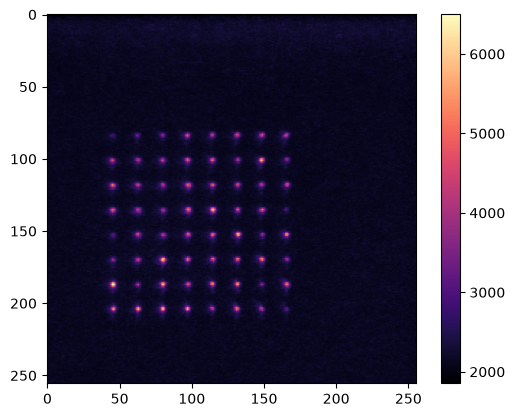

In [19]:
plt.imshow(first.mean(axis=0), cmap="magma")
plt.colorbar()

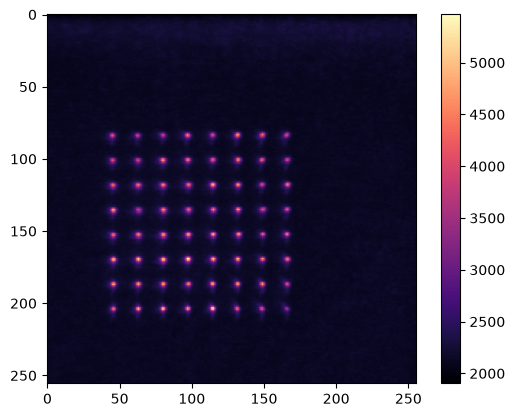

In [20]:
ds = Dataset(824) 
images = ds.get_dict(["hamcam_images"])["hamcam_images"]  # (n_points, 2, H, W)
first, second = images[:, 0], images[:, 1]

plt.imshow(first.mean(axis=0), cmap="magma")
plt.colorbar()

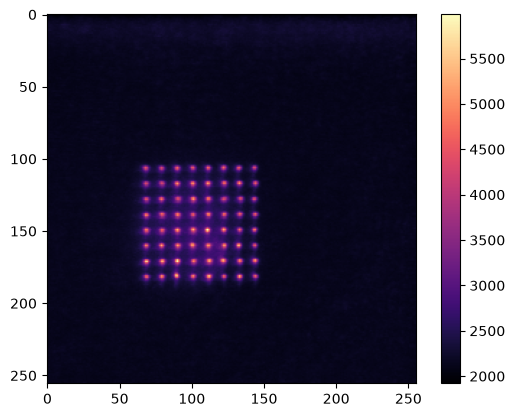

In [23]:
ds = Dataset(827) 
images = ds.get_dict(["hamcam_images"])["hamcam_images"]  # (n_points, 2, H, W)
first, second = images[:, 0], images[:, 1]

plt.imshow(first.mean(axis=0), cmap="magma")
plt.colorbar()

In [24]:
import pytweezer.analysis.analysis as an

Looking for trap sites...
64 Atoms Detected.


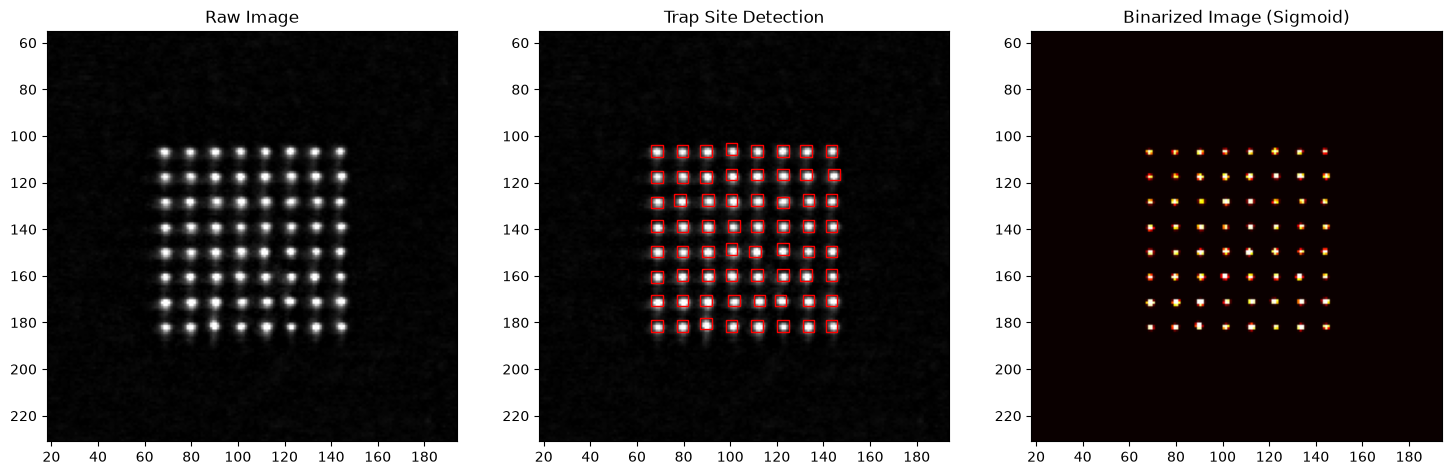

In [32]:
feature_size, window = 10, 5

img_average = first.mean(axis=0)
img_average_filtered = an.morphological_tophat_high_pass(img_average, feature_size=feature_size)
grid_positions, detection_threshold = an.detect_trap_sites(img_average_filtered, 8*8, detection_step=100)
an.visualize_results(img_average_filtered, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in first]

Trap (0) Loading Probability : 57.00 %
Trap (1) Loading Probability : 48.00 %
Trap (2) Loading Probability : 60.00 %
Trap (3) Loading Probability : 58.00 %
Trap (4) Loading Probability : 58.00 %
Trap (5) Loading Probability : 62.00 %
Trap (6) Loading Probability : 56.00 %
Trap (7) Loading Probability : 54.00 %
Trap (8) Loading Probability : 62.00 %
Trap (9) Loading Probability : 60.00 %
Trap (10) Loading Probability : 62.00 %
Trap (11) Loading Probability : 64.00 %
Trap (12) Loading Probability : 62.00 %
Trap (13) Loading Probability : 58.00 %
Trap (14) Loading Probability : 56.00 %
Trap (15) Loading Probability : 57.00 %
Trap (16) Loading Probability : 58.00 %
Trap (17) Loading Probability : 59.00 %
Trap (18) Loading Probability : 65.00 %
Trap (19) Loading Probability : 58.00 %
Trap (20) Loading Probability : 56.00 %
Trap (21) Loading Probability : 61.00 %
Trap (22) Loading Probability : 56.00 %
Trap (23) Loading Probability : 54.00 %
Trap (24) Loading Probability : 57.00 %
Trap (25) 

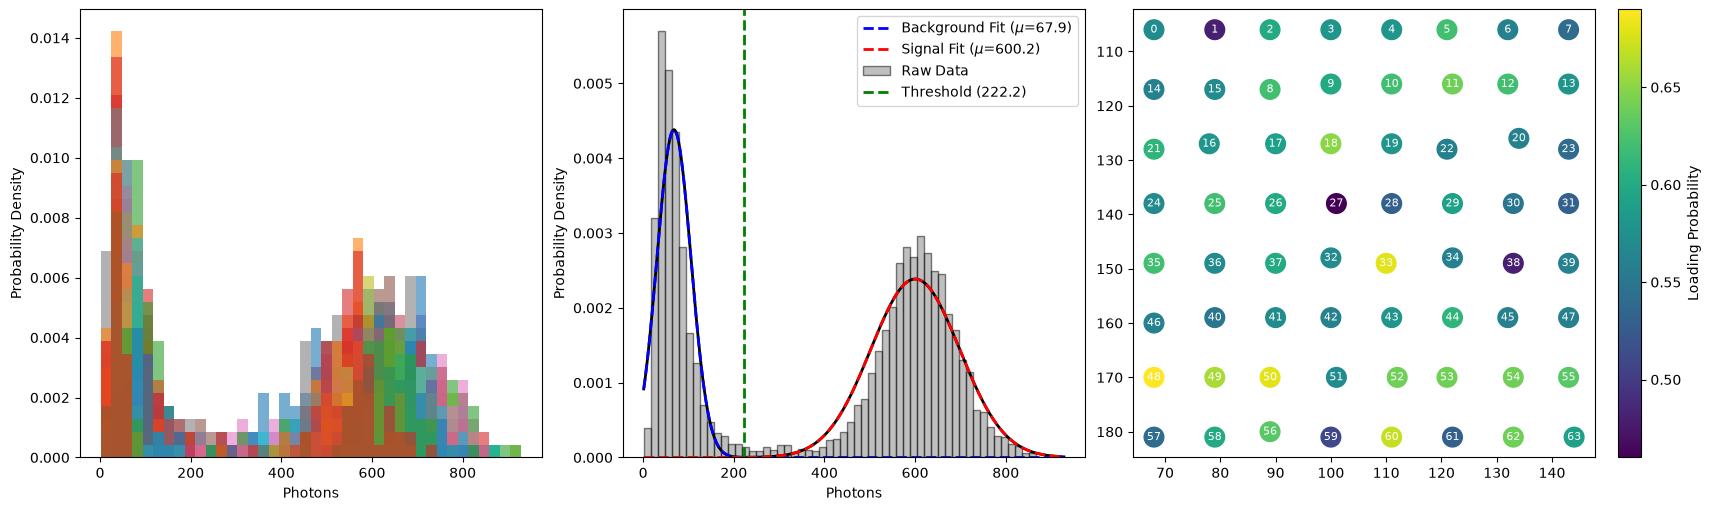

In [28]:
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)

Trap (0) Loading Probability : 56.00 %
Trap (1) Loading Probability : 48.00 %
Trap (2) Loading Probability : 58.00 %
Trap (3) Loading Probability : 57.00 %
Trap (4) Loading Probability : 58.00 %
Trap (5) Loading Probability : 59.00 %
Trap (6) Loading Probability : 56.00 %
Trap (7) Loading Probability : 53.00 %
Trap (8) Loading Probability : 62.00 %
Trap (9) Loading Probability : 59.00 %
Trap (10) Loading Probability : 61.00 %
Trap (11) Loading Probability : 64.00 %
Trap (12) Loading Probability : 61.00 %
Trap (13) Loading Probability : 58.00 %
Trap (14) Loading Probability : 56.00 %
Trap (15) Loading Probability : 55.00 %
Trap (16) Loading Probability : 56.00 %
Trap (17) Loading Probability : 58.00 %
Trap (18) Loading Probability : 65.00 %
Trap (19) Loading Probability : 58.00 %
Trap (20) Loading Probability : 56.00 %
Trap (21) Loading Probability : 54.00 %
Trap (22) Loading Probability : 61.00 %
Trap (23) Loading Probability : 55.00 %
Trap (24) Loading Probability : 57.00 %
Trap (25) 

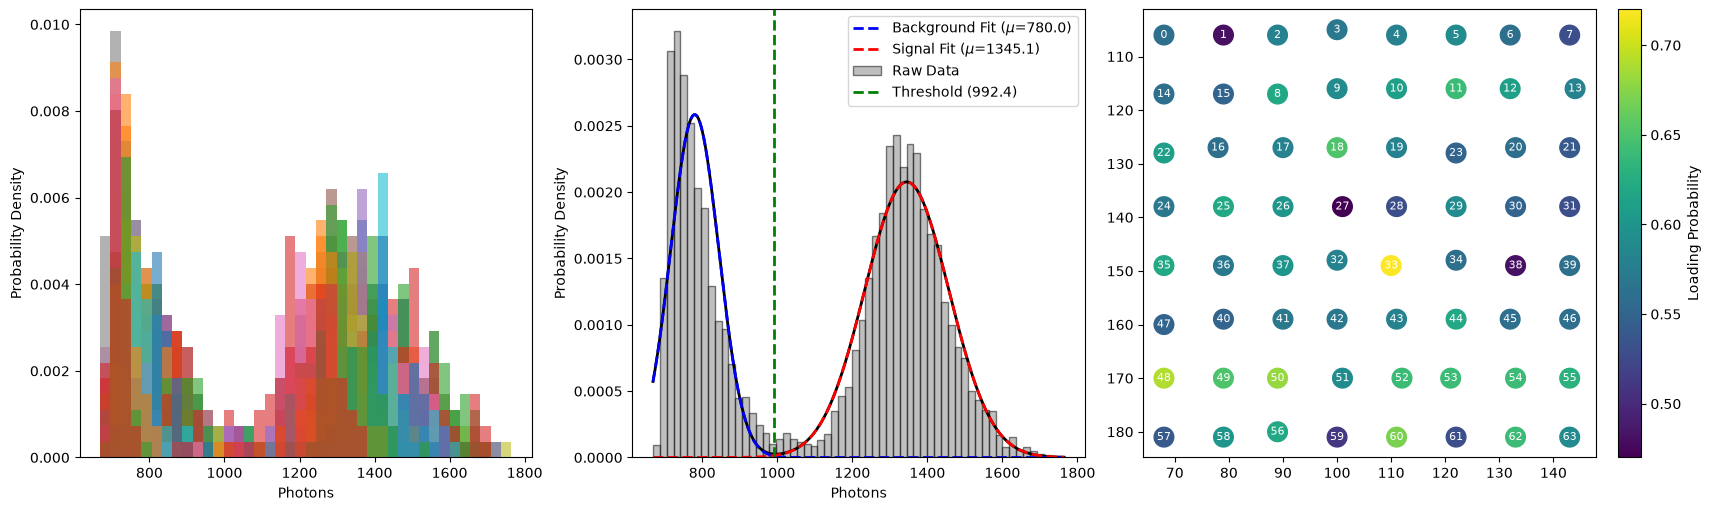

In [33]:
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(first, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)